# EMQA_L1_mix_shares

**Romania: shares of generation by source, 2015, last full year and current year**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_mix_shares/EMQA_L1_mix_shares.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Shares of Romanian electricity generation by source in 2015, in the last full year and in January to the cut-off month of the current year (hours reported in both the current and the previous year); prints the change of coal output, the growth of metered solar and the like-for-like change of nuclear output.

**Data:** 2015, 2025 full years; Jan-Oct 2026, hours reported in both 2025 and 2026. **Source:** energy-charts.info (Fraunhofer ISE); ENTSO-E (Transelectrica data for Romania).

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# Romanian generation by source and load, hourly mean MW (UTC, interval start)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
GH = GH.loc[GH.index < END_UTC]
# Romanian generation by source, daily mean MW (CET day)
G = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet').loc[:END]

data cut-off: 2026-10-31


## Computation

In [4]:
# source groups: a group is reported in an hour only if all its parts are reported
GRP = {'Hydro': ['hydro_run_of_river', 'hydro_water_reservoir'], 'Coal': ['brown_coal_lignite', 'hard_coal'],
       'Nuclear': ['nuclear'], 'Gas': ['gas'], 'Wind': ['wind_onshore'], 'Solar': ['solar'], 'Biomass': ['biomass']}
yr = GH.index.year
full_years = [y for y in sorted(set(yr)) if y < Y]
mix, cov = {}, {}
for k, cols in GRP.items():
    s = GH[cols].sum(axis=1, min_count=len(cols))
    mix[k] = s.groupby(yr).sum() / 1e6                           # TWh = sum of hourly mean MW x 1 h / 1e6
    cov[k] = s.notna().groupby(yr).mean()                        # share of hours reported
mix, cov = pd.DataFrame(mix), pd.DataFrame(cov)
share = mix.div(mix.sum(axis=1), axis=0) * 100

def lfl_block(cols, y0, y1):
    """Jan..cut-off month of y1 vs the same months of y0, over the hours reported in BOTH years (TWh)."""
    s = GH[cols].sum(axis=1, min_count=len(cols))
    a = s[(s.index.year == y1) & (s.index.month <= END.month)]
    b_ = s[(s.index.year == y0) & (s.index.month <= END.month)]
    A = pd.Series(a.values, index=a.index.strftime('%m-%d %H'))
    B = pd.Series(b_.values, index=b_.index.strftime('%m-%d %H'))
    A, B = A[~A.index.duplicated()], B[~B.index.duplicated()]
    both = pd.concat([A.rename('a'), B.rename('b')], axis=1).dropna()
    return {'ytd': fl(both['a'].sum() / 1e6, 2), 'prev': fl(both['b'].sum() / 1e6, 2),
            'chg': fl((both['a'].sum() / both['b'].sum() - 1) * 100, 1), 'ytd_own': fl(A.sum() / 1e6, 2)}

L = {k: lfl_block(c, Y - 1, Y) for k, c in GRP.items()}
tot_a = sum(L[k]['ytd'] for k in GRP)
for k in GRP:
    L[k]['share_ytd'] = fl(L[k]['ytd'] / tot_a * 100, 1)
gn = G.loc[str(Y), 'nuclear']

show('mix.first', 'first full year', full_years[0])
show('mix.last', 'last full year', full_years[-1])
show('mix.coal_change_pct', 'coal output, change first -> last full year, %',
     fl((mix.loc[full_years[-1], 'Coal'] / mix.loc[full_years[0], 'Coal'] - 1) * 100, 1))
show('mix.solar_x', 'metered solar, last / first full year', fl(mix.loc[full_years[-1], 'Solar'] / mix.loc[full_years[0], 'Solar'], 1))
show('mix.lfl.Nuclear.chg', f'nuclear, Jan-{MON_EN[END.month - 1]} {Y} vs {Y - 1}, %', L['Nuclear']['chg'])
show('nuclear.missing_days', f'days of {Y} without reported nuclear output', int(gn.isna().sum()))

first full year = 2015   [mix.first]
last full year = 2025   [mix.last]
coal output, change first -> last full year, % = -63.9   [mix.coal_change_pct]
metered solar, last / first full year = 2.2   [mix.solar_x]
nuclear, Jan-Oct 2026 vs 2025, % = -31.3   [mix.lfl.Nuclear.chg]
days of 2026 without reported nuclear output = 29   [nuclear.missing_days]


## Chart

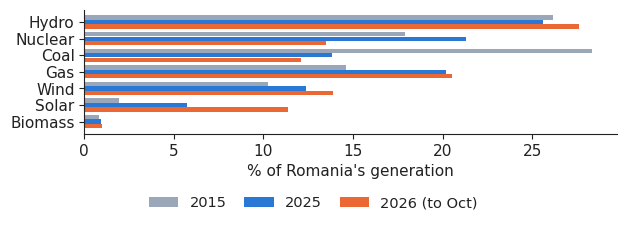

In [5]:
ORDER = ['Hydro', 'Nuclear', 'Coal', 'Gas', 'Wind', 'Solar', 'Biomass']
SCOL = {'Hydro': PAL['RO'], 'Nuclear': PAL['c7'], 'Coal': '#5b4a3a', 'Gas': PAL['DE_LU'], 'Wind': PAL['HU'],
        'Solar': PAL['BG'], 'Biomass': PAL['c6']}
fig, ax = plt.subplots(figsize=(6.4, 2.3))
yy = np.arange(len(ORDER))
for i, (lab, vals, col) in enumerate([('2015', [share.loc[2015, k] for k in ORDER], '#9aa7b8'),
                                      (str(full_years[-1]), [share.loc[full_years[-1], k] for k in ORDER], PAL['RO']),
                                      (f'{Y} (to {MON_EN[END.month - 1]})', [L[k]['share_ytd'] for k in ORDER], PAL['DE_LU'])]):
    ax.barh(yy + (i - 1) * 0.27, vals, height=0.26, color=col, label=lab)
ax.set_yticks(yy)
ax.set_yticklabels(ORDER)
ax.invert_yaxis()
ax.set_xlabel("% of Romania's generation")
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('mix_shares.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()